# Módulo 20 — Árvores implícitas de Derman-Kani-Chriss: construção e visualização interativa

**Curso:** Derivativos com Python. Último módulo do complemento, depois das árvores de juros do Módulo 18. Material de base: Derman, Kani e Chriss, "Implied Trinomial Trees of the Volatility Smile", *Journal of Derivatives* (1996); Derman e Kani, "Riding on a Smile", *Risk* (1994); Dupire, "Pricing with a Smile", *Risk* (1994); Clewlow e Strickland, *Implementing Derivatives Models* (1998), sobre árvores implícitas.

## O que você vai conseguir fazer ao final

1. Explicar por que uma árvore com volatilidade constante não reproduz o sorriso, e o que é volatilidade local.
2. Montar o espaço de estados de uma árvore trinomial, inclusive com passos de tempo desiguais e com nós que acompanham o forward (a árvore "que curva").
3. Deduzir e implementar as equações de Derman-Kani-Chriss: probabilidades de transição a partir de calls e puts de mercado e preços de Arrow-Debreu por indução para a frente.
4. Diagnosticar probabilidades negativas, aplicar o *override* e escolher um espaço de estados que o evite.
5. Ler a volatilidade local na árvore, conferir a regra do "dobro da inclinação" e precificar americanas e barreiras.
6. Usar o widget interativo do final para construir e desenhar árvores, nó a nó.

## Onde estamos

No Módulo 6 a árvore CRR tinha uma única volatilidade; no Módulo 18 a árvore de Hull-White foi ajustada à curva de juros pelos preços de Arrow-Debreu. Aqui juntamos as duas ideias para ações e índices: em vez de ajustar uma curva, a árvore é ajustada a uma **superfície de volatilidade implícita**. O resultado é um modelo de volatilidade local, $dS = rS\,dt + \sigma_{loc}(S, t)S\,dW$, em forma discreta. Todos os dados são sintéticos.

## 0. Preparação

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.stats import norm
from scipy.optimize import brentq
from IPython.display import display

AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a84"
MAGENTA = "#c43b6b"

plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "lines.linewidth": 2.0, "legend.frameon": False,
    "font.size": 10,
})


def f3(x):
    """Formata com três casas decimais no padrão brasileiro."""
    return f"{x:,.3f}".replace(",", "§").replace(".", ",").replace("§", ".")


def tabela(df):
    """Exibe um DataFrame com os números reais em três casas decimais."""
    def fmt(v):
        if isinstance(v, (float, np.floating)):
            return "n/d" if np.isnan(v) else f3(v)
        return v
    display(df.map(fmt))


_checks = {"n": 0}


def ok(condicao, mensagem):
    """Verificação do laboratório: interrompe o notebook se a conta não fechar."""
    assert bool(condicao), f"FALHOU: {mensagem}"
    _checks["n"] += 1
    print(f"OK — {mensagem}")


def bs(S, K, T, r, sig, tipo="call"):
    """Black-Scholes sem dividendos."""
    d1 = (np.log(S / K) + (r + 0.5 * sig**2) * T) / (sig * np.sqrt(T))
    d2 = d1 - sig * np.sqrt(T)
    if tipo == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)


def vol_impl(preco, S, K, T, r):
    """Volatilidade implícita de uma call por bissecção robusta (brentq)."""
    return brentq(lambda s: bs(S, K, T, r, s) - preco, 1e-4, 3.0)

## 1. O sorriso e a volatilidade local

Se o mercado usasse Black-Scholes, todas as opções de mesmo vencimento teriam a mesma volatilidade implícita. Não têm: em ações e índices, strikes baixos negociam com volatilidade maior (a inclinação negativa do Módulo 2), e a curva costuma ser convexa. Uma árvore CRR com um único $\sigma$ acerta, no máximo, um strike por vencimento.

Vamos usar um sorriso sintético, função da *log-moneyness* em relação ao forward, $m = \ln(K/F_t)$ com $F_t = S_0e^{rt}$:

$$\sigma_{imp}(K, t) = \max\left(\sigma_{ATM} + b\,m + c\,m^2,\ 1\%\right).$$

A pergunta de Dupire (1994) e de Derman e Kani (1994) é: existe uma difusão com volatilidade dependente só do preço e do tempo, $\sigma_{loc}(S, t)$, que reproduza **todos** esses preços ao mesmo tempo? A resposta é sim, e ela é única. Em tempo contínuo, sem dividendos,

$$\sigma_{loc}^2(K, T) = \frac{\partial_T C + rK\,\partial_K C}{\tfrac12 K^2\,\partial_{KK} C},$$

em que $C(K, T)$ é a superfície de preços de calls. A fórmula exige derivadas segundas de preços observados, o que é instável. A árvore implícita é a versão discreta e construtiva dessa mesma ideia: ela extrai a volatilidade local nó a nó, sem derivar numericamente a superfície.

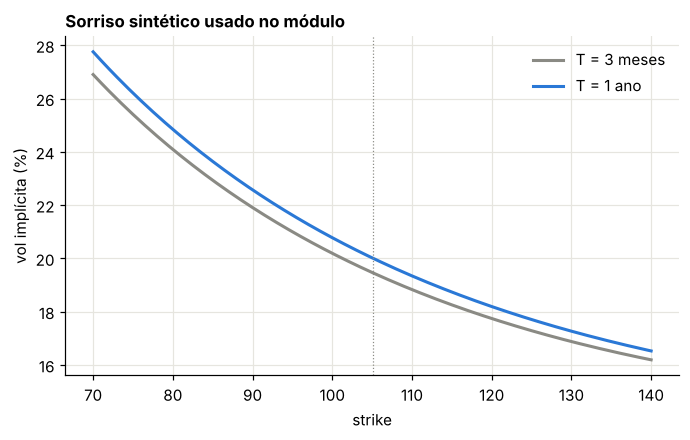

vol implícita em 1 ano: K = 80 → 24,843 %; K = 120 → 18,190 %
OK — inclinação negativa: strikes baixos mais caros em vol


In [2]:
S0, R = 100.0, 0.05


def fazer_sorriso(S0, r, s_atm=0.20, inclin=0.0, curv=0.0):
    """Sorriso quadrático em m = ln(K/F_t), com piso de 1%."""
    def sorriso(K, t):
        m = np.log(K / (S0 * np.exp(r * t)))
        return np.maximum(s_atm + inclin * m + curv * m**2, 0.01)
    return sorriso


SORRISO = fazer_sorriso(S0, R, 0.20, -0.15, 0.10)
K = np.linspace(70, 140, 141)
fig, ax = plt.subplots()
for T, cor, rot in [(0.25, CINZA, "T = 3 meses"), (1.0, AZUL, "T = 1 ano")]:
    ax.plot(K, 100 * SORRISO(K, T), color=cor, label=rot)
ax.axvline(S0 * np.exp(R), color=CINZA, lw=0.8, ls=":")
ax.set(title="Sorriso sintético usado no módulo", xlabel="strike", ylabel="vol implícita (%)")
ax.legend()
plt.show()
print("vol implícita em 1 ano: K = 80 →", f3(100 * SORRISO(80, 1)), "%; K = 120 →", f3(100 * SORRISO(120, 1)), "%")
ok(SORRISO(80, 1) > SORRISO(105.127, 1) > SORRISO(130, 1) - 0.02, "inclinação negativa: strikes baixos mais caros em vol")

## 2. Ingredientes de uma árvore implícita

Uma árvore trinomial recombinante tem três ingredientes, e a ordem importa:

1. **Espaço de estados.** Os preços dos nós em cada data $t_n$. No nível $n$ há $2n + 1$ nós, que numeramos **de cima para baixo**: $S_1 > S_2 > \dots > S_{2n+1}$. O nó $i$ liga-se aos nós $i$, $i+1$ e $i+2$ do nível seguinte, que chamaremos $s_i > s_{i+1} > s_{i+2}$.
2. **Probabilidades de transição.** Do nó $i$: $p_i$ para cima, $1 - p_i - q_i$ para o meio, $q_i$ para baixo.
3. **Preços de Arrow-Debreu.** $\lambda_i$ é o valor hoje de receber 1 se o nó $i$ for atingido. Começa em $\lambda = 1$ na raiz e avança por indução para a frente, como no Módulo 18:

$$\Lambda_k = e^{-r\Delta t_n}\sum_i \lambda_i\,\pi_{i \to k}.$$

No método de Derman, Kani e Chriss (DKC), o espaço de estados é **escolhido livremente** e só depois as probabilidades são calculadas para reproduzir os preços de mercado. É essa liberdade que permite árvores com passos desiguais e árvores cujos nós "curvam".

### Três espaços de estados

Seja $\Delta t_n = t_n - t_{n-1}$ o passo que chega ao nível $n$. Em log-preço, os nós do nível $n$ são $x_{n,j} = c_n + j\,h_n$, $j = n, \dots, -n$, com espaçamento $h_n = f\,\sigma_{ATM}\sqrt{3\Delta t_n}$. O fator $\sqrt 3$ é o da árvore trinomial padrão, em que as probabilidades com volatilidade constante seriam $1/6$, $2/3$ e $1/6$; $f$ é um fator de espaçamento. O centro $c_n$ define o tipo:

- **centrado em $S_0$:** $c_n = \ln S_0$ (a árvore horizontal da figura de DKC com passos 0, 1, 3, 6);
- **centrado no forward:** $c_n = \ln S_0 + r t_n$. Em escala de preço, os ramos de cima se afastam e os de baixo se comprimem: é a árvore "que curva";
- **espaçamento pelo sorriso:** o centro segue o forward e cada degrau usa a vol implícita no próprio nível, $x_{j+1} = x_j + f\,\sigma_{imp}(e^{x_j}, t_n)\sqrt{3\Delta t_n}$. Onde o sorriso é alto, os nós se abrem.

In [3]:
def grade(T, N, tipo="uniforme"):
    """Datas da árvore. 'crescente' usa números triangulares: 0, 1, 3, 6, 10, ... (reescalados)."""
    k = np.arange(N + 1)
    return T * k * (k + 1) / (N * (N + 1)) if tipo == "crescente" else T * k / N


def espaco_estados(S0, r, tempos, modo, sorriso, fator=1.0):
    """Lista de arrays: nível n com 2n+1 preços em ordem decrescente."""
    niveis = [np.array([S0])]
    for n in range(1, len(tempos)):
        dt, t = tempos[n] - tempos[n - 1], tempos[n]
        Fc = S0 * np.exp(r * t)
        c = np.log(S0) + (0.0 if modo == "spot" else r * t)
        if modo != "smile":
            h = fator * sorriso(Fc, t) * np.sqrt(3 * dt)
            x = c + np.arange(n, -n - 1, -1) * h
        else:
            hmax = 4 * sorriso(Fc, t) * np.sqrt(3 * dt)    # trava contra degraus explosivos
            x = np.empty(2 * n + 1)
            x[n] = c
            for k in range(n - 1, -1, -1):
                x[k] = x[k + 1] + min(fator * sorriso(np.exp(x[k + 1]), t) * np.sqrt(3 * dt), hmax)
            for k in range(n + 1, 2 * n + 1):
                x[k] = x[k - 1] - min(fator * sorriso(np.exp(x[k - 1]), t) * np.sqrt(3 * dt), hmax)
        niveis.append(np.exp(x))
    return niveis


def desenhar_arvore(ax, tempos, niveis, arv=None, rotulos=False, cor="vl", escala_t=1.0, s_ref=None):
    """Desenha a árvore. Com arv, a espessura da aresta segue a probabilidade e a cor do nó, a vol local."""
    segs, larg = [], []
    for n in range(len(tempos) - 1):
        for i, s in enumerate(niveis[n]):
            pr = [1 / 3] * 3 if arv is None else [arv["p"][n][i], 1 - arv["p"][n][i] - arv["q"][n][i], arv["q"][n][i]]
            for k in range(3):
                if pr[k] > 1e-12:
                    segs.append([(tempos[n] * escala_t, s), (tempos[n + 1] * escala_t, niveis[n + 1][i + k])])
                    larg.append(0.4 + 2.2 * pr[k])
    ax.add_collection(LineCollection(segs, linewidths=larg, colors=CINZA, alpha=0.55, zorder=1))
    for n, nivel in enumerate(niveis):
        tt = np.full(len(nivel), tempos[n] * escala_t)
        if arv is not None and n < len(tempos) - 1 and cor == "vl":
            v = (arv["vl"][n] - s_ref) / (0.5 * s_ref)
            cores = plt.cm.coolwarm(0.5 + 0.5 * np.clip(v, -1, 1))
            borda = np.where(arv["ovr"][n], MAGENTA, "#555555")
            ax.scatter(tt, nivel, s=26, c=cores, edgecolors=borda, linewidths=np.where(arv["ovr"][n], 1.6, 0.5), zorder=3)
        else:
            ax.scatter(tt, nivel, s=22, color="#d9d8d2" if arv is not None else AZUL, edgecolors="#555555", linewidths=0.5, zorder=3)
        if rotulos:
            for s in nivel:
                ax.annotate(f"{s:.2f}".replace(".", ","), (tempos[n] * escala_t, s), textcoords="offset points",
                            xytext=(0, 6), ha="center", fontsize=8)
    ax.set_xticks(np.asarray(tempos) * escala_t)
    ax.grid(axis="x", visible=False)

### Laboratório 1 — as duas figuras de DKC

A figura (a) de Derman, Kani e Chriss mostra uma árvore com datas 0, 1, 3 e 6, centrada no preço inicial, com volatilidade ATM de 10% e juros de 3%. A figura (b) mostra uma árvore de 10 passos cujos nós sobem com o forward e se abrem em escala de preço. Reproduzimos as duas estruturas com o nosso gerador (os números exatos do artigo dependem de detalhes de espaçamento que não seguimos à risca).

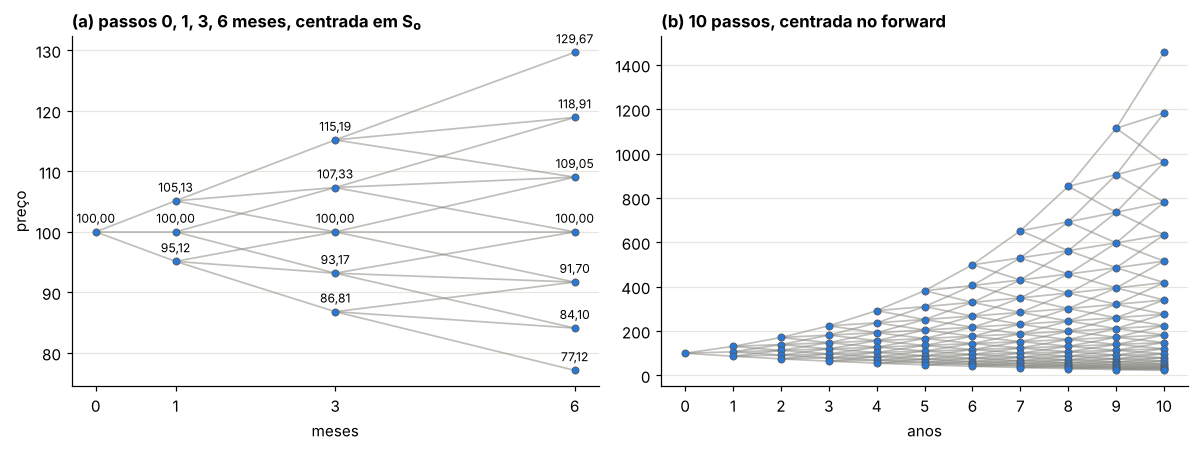

t = 0 mês(es): 100,000
t = 1 mês(es): 105,127  100,000  95,123
t = 3 mês(es): 115,191  107,327  100,000  93,173  86,812
t = 6 mês(es): 129,668  118,911  109,046  100,000  91,704  84,097  77,120
OK — cada nível n tem 2n + 1 nós
OK — nós em ordem estritamente decrescente
OK — na figura (b), o nó central segue o forward S₀e^{rt}
OK — em escala de preço, os ramos de cima se abrem bem mais que os de baixo


In [4]:
TEMPOS_A = np.array([0, 1, 3, 6]) / 12
NIV_A = espaco_estados(100.0, 0.03, TEMPOS_A, "spot", fazer_sorriso(100.0, 0.03, 0.10), 1.0)
TEMPOS_B = grade(10.0, 10)
NIV_B = espaco_estados(100.0, 0.06, TEMPOS_B, "forward", fazer_sorriso(100.0, 0.06, 0.12), 1.0)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
desenhar_arvore(axs[0], TEMPOS_A, NIV_A, rotulos=True, escala_t=12)
axs[0].set(title="(a) passos 0, 1, 3, 6 meses, centrada em S₀", xlabel="meses", ylabel="preço")
desenhar_arvore(axs[1], TEMPOS_B, NIV_B)
axs[1].set(title="(b) 10 passos, centrada no forward", xlabel="anos")
plt.tight_layout()
plt.show()

for n, nivel in enumerate(NIV_A):
    print(f"t = {12 * TEMPOS_A[n]:.0f} mês(es):", "  ".join(f3(s) for s in nivel))
ok(all(len(nv) == 2 * n + 1 for niv in (NIV_A, NIV_B) for n, nv in enumerate(niv)), "cada nível n tem 2n + 1 nós")
ok(all(np.all(np.diff(nivel) < 0) for nivel in NIV_A + NIV_B), "nós em ordem estritamente decrescente")
ok(np.isclose(NIV_B[10][10], 100 * np.exp(0.06 * 10)), "na figura (b), o nó central segue o forward S₀e^{rt}")
ok((NIV_B[10][0] - NIV_B[10][10]) > 3 * (NIV_B[10][10] - NIV_B[10][-1]), "em escala de preço, os ramos de cima se abrem bem mais que os de baixo")

Repare na figura (a): os degraus crescem com o passo de tempo. O primeiro, de 1 mês, dá nós em torno de $\pm 5\%$; o de 3 para 6 meses é maior. Como o centro não acompanha o forward, toda a deriva de juros terá de ser absorvida pelas probabilidades. Na figura (b), o centro sobe com $e^{rt}$ e o espaçamento constante em log vira, em preço, um leque assimétrico.

## 3. As equações de Derman-Kani-Chriss

Fixe o nível $n$, com nós $S_i$, preços de Arrow-Debreu $\lambda_i$ conhecidos e forwards $F_i = S_ie^{r\Delta t}$, em que $\Delta t = t_{n+1} - t_n$. Queremos $p_i$ e $q_i$ para todos os nós. São $2(2n+1)$ incógnitas.

**Condição do forward.** Sob a medida neutra ao risco, o preço esperado no passo seguinte é o forward:

$$p_i\,s_i + (1 - p_i - q_i)\,s_{i+1} + q_i\,s_{i+2} = F_i \quad\Longleftrightarrow\quad p_i(s_i - s_{i+1}) + q_i(s_{i+2} - s_{i+1}) = F_i - s_{i+1}.$$

São $2n + 1$ equações. As outras $2n + 1$ vêm de opções de mercado.

**Condição das calls.** Tome a call com vencimento $t_{n+1}$ e strike exatamente no nó $s_{i+1}$. Seu preço é a soma, sobre os nós do nível $n$, de $\lambda_j$ vezes o valor descontado do payoff no passo seguinte. Para os nós acima de $i$ ($j < i$), os três sucessores estão acima do strike, então o payoff é linear e sua esperança é $F_j - s_{i+1}$. Para o nó $i$, só o ramo de cima paga. Nós abaixo de $i$ não pagam nada. Logo

$$e^{r\Delta t}\,C(s_{i+1}, t_{n+1}) = \sum_{j<i}\lambda_j\,(F_j - s_{i+1}) + \lambda_i\,p_i\,(s_i - s_{i+1}),$$

$$p_i = \frac{e^{r\Delta t}C(s_{i+1}, t_{n+1}) - \sum_{j<i}\lambda_j(F_j - s_{i+1})}{\lambda_i\,(s_i - s_{i+1})}.$$

Com $p_i$, a condição do forward dá $q_i$. A recursão começa no topo ($i = 1$, soma vazia) e desce.

**Condição das puts.** Para a metade de baixo, DKC usam puts com strike $s_{i+1}$, começando de baixo:

$$e^{r\Delta t}\,P(s_{i+1}, t_{n+1}) = \sum_{j>i}\lambda_j\,(s_{i+1} - F_j) + \lambda_i\,q_i\,(s_{i+1} - s_{i+2}).$$

Por que trocar? Uma call com strike muito baixo está profundamente dentro do dinheiro: o seu preço é quase todo valor intrínseco, a soma $\sum_{j<i}\lambda_j(F_j - K)$ é enorme, e a diferença que sobra para determinar $p_i$ seria pequena e cheia de erro de cancelamento. Usar sempre a opção fora do dinheiro evita isso. O nó central fica com as calls.

**O preço das opções.** Os preços $C$ e $P$ vêm do mercado, aqui do sorriso pela fórmula de Black-Scholes com a vol implícita do strike. A árvore não usa Black-Scholes como modelo; usa Black-Scholes só como tradutor de vol implícita em preço.

**Volatilidade local no nó.** Com as probabilidades, a variância do passo seguinte define a volatilidade local:

$$\sigma_{loc}^2(S_i, t_n)\,F_i^2\,\Delta t = p_i(s_i - F_i)^2 + (1 - p_i - q_i)(s_{i+1} - F_i)^2 + q_i(s_{i+2} - F_i)^2.$$

### O *override* de DKC

Nada garante que as fórmulas acima deem probabilidades em $[0, 1]$. Se o sorriso pede, num nó, uma variância maior do que os três sucessores conseguem oferecer, ou se o forward cai fora do intervalo entre eles, aparece $p_i < 0$, $q_i < 0$ ou $p_i + q_i > 1$. DKC então descartam a informação da opção naquele nó e escolhem probabilidades que só respeitam o forward. Se $s_{i+1} < F_i < s_i$,

$$p_i = \frac12\left(\frac{F_i - s_{i+1}}{s_i - s_{i+1}} + \frac{F_i - s_{i+2}}{s_i - s_{i+2}}\right), \qquad q_i = \frac12\,\frac{s_i - F_i}{s_i - s_{i+2}},$$

e, se $s_{i+2} < F_i < s_{i+1}$,

$$p_i = \frac12\,\frac{F_i - s_{i+2}}{s_i - s_{i+2}}, \qquad q_i = \frac12\left(\frac{s_{i+1} - F_i}{s_{i+1} - s_{i+2}} + \frac{s_i - F_i}{s_i - s_{i+2}}\right).$$

A leitura é simples: é a média de duas árvores binomiais, cada uma ligando o nó a dois sucessores e respeitando o forward. O preço é perder o ajuste à opção daquele strike. Um override ocasional nas pontas, onde $\lambda$ é desprezível, não incomoda; muitos overrides no miolo indicam um espaço de estados mal escolhido.

In [5]:
def override(F, a, b, c):
    """Probabilidades (p, q) de DKC que só respeitam o forward. a > b > c são os sucessores."""
    if F >= a:
        return 1.0, 0.0
    if F <= c:
        return 0.0, 1.0
    if F > b:
        return 0.5 * ((F - b) / (a - b) + (F - c) / (a - c)), 0.5 * (a - F) / (a - c)
    return 0.5 * (F - c) / (a - c), 0.5 * ((b - F) / (b - c) + (a - F) / (a - c))


def arvore_implicita(S0, r, tempos, sorriso, niveis):
    """Árvore trinomial implícita de Derman-Kani-Chriss (1996)."""
    N = len(tempos) - 1
    lam, P, Q, VL, OV = [np.array([1.0])], [], [], [], []
    for n in range(N):
        S, s, L = niveis[n], niveis[n + 1], lam[n]
        dt, t1 = tempos[n + 1] - tempos[n], tempos[n + 1]
        cr = np.exp(r * dt)
        F = S * cr
        m = len(S)
        p, q = np.zeros(m), np.zeros(m)
        with np.errstate(all="ignore"):
            soma = 0.0                                       # Σ_{j<i} λ_j (F_j − s_{i+1})
            for i in range(0, (m - 1) // 2 + 1):             # metade de cima e centro: calls
                K = s[i + 1]
                C = bs(S0, K, t1, r, sorriso(K, t1), "call")
                p[i] = (cr * C - soma) / (L[i] * (s[i] - K))
                q[i] = (F[i] - p[i] * (s[i] - K) - K) / (s[i + 2] - K)
                soma = np.sum(L[:i + 1] * (F[:i + 1] - s[i + 2]))   # já com o strike do próximo i
            soma = 0.0                                       # Σ_{j>i} λ_j (s_{i+1} − F_j)
            for i in range(m - 1, (m - 1) // 2, -1):         # metade de baixo: puts
                K = s[i + 1]
                Pp = bs(S0, K, t1, r, sorriso(K, t1), "put")
                q[i] = (cr * Pp - soma) / (L[i] * (K - s[i + 2]))
                p[i] = (F[i] + q[i] * (K - s[i + 2]) - K) / (s[i] - K)
                soma = np.sum(L[i:] * (s[i] - F[i:]))
        ov = ~(np.isfinite(p) & np.isfinite(q)) | (p < 0) | (q < 0) | (p + q > 1)
        for i in np.where(ov)[0]:
            p[i], q[i] = override(F[i], s[i], s[i + 1], s[i + 2])
        pm = 1 - p - q
        var = p * (s[:-2] - F)**2 + pm * (s[1:-1] - F)**2 + q * (s[2:] - F)**2
        L1 = np.zeros(m + 2)
        L1[:-2] += L * p
        L1[1:-1] += L * pm
        L1[2:] += L * q
        lam.append(L1 / cr)
        P.append(p); Q.append(q); VL.append(np.sqrt(var / (F**2 * dt))); OV.append(ov)
    return dict(S=niveis, lam=lam, p=P, q=Q, vl=VL, ovr=OV, t=np.asarray(tempos, float), r=r)


def preco_arvore(arv, payoff, americana=False, barreira=None):
    """Indução para trás. payoff recebe um array de preços; barreira = nível 'down-and-out'."""
    S, t, r = arv["S"], arv["t"], arv["r"]
    V = payoff(S[-1])
    if barreira is not None:
        V = np.where(S[-1] <= barreira, 0.0, V)
    for n in range(len(t) - 2, -1, -1):
        d = np.exp(-r * (t[n + 1] - t[n]))
        p, q = arv["p"][n], arv["q"][n]
        V = d * (p * V[:-2] + (1 - p - q) * V[1:-1] + q * V[2:])
        if americana:
            V = np.maximum(V, payoff(S[n]))
        if barreira is not None:
            V = np.where(S[n] <= barreira, 0.0, V)
    return V[0]


def massa_override(arv):
    """Maior fração de Arrow-Debreu, num mesmo nível, em nós com override."""
    return max((L * o).sum() / L.sum() for L, o in zip(arv["lam"], arv["ovr"]))

### Laboratório 2 — sorriso plano: a árvore implícita vira uma árvore de volatilidade constante

Primeiro o caso em que sabemos a resposta. Com sorriso plano em 20%, a volatilidade local tem de ser 20% em todo nó, os preços de Arrow-Debreu do último nível têm de somar o fator de desconto, e o preço descontado tem de ser martingal: $\sum_k \Lambda_k S_k = S_0$.

In [6]:
T, N = 1.0, 40
t40 = grade(T, N)
plano = fazer_sorriso(S0, R, 0.20)
arv_p = arvore_implicita(S0, R, t40, plano, espaco_estados(S0, R, t40, "forward", plano, 1.0))

def vl_relevante(a, n0, n1):
    """Vol locais dos níveis n0..n1−1 em nós com peso de Arrow-Debreu relevante."""
    return np.concatenate([a["vl"][n][a["lam"][n] > 1e-4 * a["lam"][n].sum()] for n in range(n0, n1)])


print("vol local no nível 0:", f3(100 * arv_p["vl"][0][0]), "%; nível 2:", ", ".join(f3(100 * v) for v in arv_p["vl"][2]), "%")
vl_miolo = vl_relevante(arv_p, 10, N)
print("vol local dos níveis 10 a 39: mín", f3(100 * vl_miolo.min()), "% · máx", f3(100 * vl_miolo.max()), "%")
print("Σλ(T) =", f"{arv_p['lam'][-1].sum():.10f}", " e^{-rT} =", f"{np.exp(-R * T):.10f}")
print("Σλ·S(T) =", f"{(arv_p['lam'][-1] * arv_p['S'][-1]).sum():.10f}")
ok(sum(o.sum() for o in arv_p["ovr"]) == 0, "sorriso plano: nenhum override")
ok(np.allclose(vl_miolo, 0.20, atol=3e-3), "sorriso plano: a partir do nível 10, vol local de 20% (± 0,3 p.p.) nos nós com peso relevante")
ok(arv_p["vl"][0][0] > 0.22, "no primeiro passo, a vol local sai acima de 20%: três nós imitando uma lognormal")
ok(np.isclose(arv_p["lam"][-1].sum(), np.exp(-R * T), atol=1e-12), "Σλ no vencimento = fator de desconto")
ok(np.isclose((arv_p["lam"][-1] * arv_p["S"][-1]).sum(), S0, atol=1e-9), "preço descontado é martingal: ΣλS = S₀")

err = [preco_arvore(arv_p, lambda x: np.maximum(x - k, 0)) - bs(S0, k, T, R, 0.20) for k in (80, 100, 120)]
print("erro da call (árvore − BS) em K = 80, 100, 120:", ", ".join(f3(e) for e in err))
ok(max(abs(e) for e in err) < 0.1, "com 40 passos, calls fora dos nós a menos de 10 centavos de Black-Scholes")

vol local no nível 0: 23,517 %; nível 2: 21,642, 20,006, 20,089, 20,006, 21,642 %
vol local dos níveis 10 a 39: mín 19,996 % · máx 20,178 %
Σλ(T) = 0.9512294245  e^{-rT} = 0.9512294245
Σλ·S(T) = 100.0000000000
OK — sorriso plano: nenhum override
OK — sorriso plano: a partir do nível 10, vol local de 20% (± 0,3 p.p.) nos nós com peso relevante
OK — no primeiro passo, a vol local sai acima de 20%: três nós imitando uma lognormal
OK — Σλ no vencimento = fator de desconto
OK — preço descontado é martingal: ΣλS = S₀
erro da call (árvore − BS) em K = 80, 100, 120: 0,001, 0,023, 0,061
OK — com 40 passos, calls fora dos nós a menos de 10 centavos de Black-Scholes


Os primeiros passos merecem atenção. Com um só nó na raiz e três sucessores, a árvore tem de reproduzir o preço contínuo de Black-Scholes da call com strike no nó central; uma distribuição de três pontos só consegue isso com variância maior, e a vol local do primeiro passo sai em torno de 23,5%. Com mais nós, a distribuição discreta se aproxima da lognormal e a vol local converge para 20%; o mesmo efeito, mais fraco, aparece nos nós da borda de cada nível, que têm peso desprezível. É um efeito de discretização, não de mercado: cai quando o primeiro passo encolhe, por exemplo com a grade crescente.

A conferência do martingal não é um acaso numérico. A soma $\sum_k \Lambda_k s_k$ é igual a $e^{-r\Delta t}\sum_i \lambda_i\,\mathbb E_i[s]$, e a condição do forward faz $\mathbb E_i[s] = F_i = S_ie^{r\Delta t}$. Logo $\sum_k\Lambda_k s_k = \sum_i\lambda_iS_i$, e assim por diante até a raiz. Vale **mesmo com overrides**, porque o override também respeita o forward.

## 4. Sorriso inclinado: calibração exata nos nós

Agora o sorriso da Seção 1, com inclinação $-0{,}15$ e convexidade $0{,}10$. Usamos o espaço de estados pelo sorriso com fator $1{,}3$.

Há uma propriedade forte: **no vencimento, as calls com strike num nó são reproduzidas exatamente**, qualquer que seja o que aconteceu antes. O último passo da construção impõe essas equações diretamente, a partir dos $\lambda$ do penúltimo nível. Pela paridade put-call, que vale na árvore porque o forward é respeitado, o mesmo vale para as puts. Só um override no último passo quebra a igualdade naquele strike.

In [7]:
FATOR = 1.3
arv = arvore_implicita(S0, R, t40, SORRISO, espaco_estados(S0, R, t40, "smile", SORRISO, FATOR))
SN = arv["S"][-1]
ov_ult = arv["ovr"][-1]

linhas, erros_nos = [], []
for k in range(1, 2 * N):
    Kk = SN[k]
    i = k - 1                         # o strike s_{i+1} é imposto pelo nó i do penúltimo nível
    if abs(np.log(Kk / (S0 * np.exp(R)))) > 0.35:
        continue
    pc = preco_arvore(arv, lambda x: np.maximum(x - Kk, 0))
    pm = bs(S0, Kk, T, R, SORRISO(Kk, T))
    if not ov_ult[i]:
        erros_nos.append(abs(pc - pm))
    linhas.append({"strike (nó)": Kk, "vol mercado (%)": 100 * SORRISO(Kk, T),
                   "vol árvore (%)": 100 * vol_impl(pc, S0, Kk, T, R), "override no último passo": "sim" if ov_ult[i] else "não"})
tabela(pd.DataFrame(linhas)[::3])
print("maior erro de preço nos nós sem override:", f"{max(erros_nos):.2e}")
print("overrides:", sum(o.sum() for o in arv["ovr"]), "de", N * N, "nós · maior massa num nível:", f3(100 * massa_override(arv)), "%")
ok(max(erros_nos) < 1e-8, "calls com strike nos nós reproduzidas exatamente (erro < 1e-8)")
ok(abs((arv["lam"][-1] * SN).sum() - S0) < 1e-9, "martingal preservado com sorriso e overrides")
ok(massa_override(arv) < 0.05, "overrides concentrados nas pontas: menos de 5% da massa de Arrow-Debreu em qualquer nível")

,strike (nó),vol mercado (%),vol árvore (%),override no último passo
0,"145,446","16,184","16,184",não
3,"120,778","18,111","18,111",não
6,"97,902","21,119","21,119",não
9,"77,007","25,638","25,638",não


maior erro de preço nos nós sem override: 2.52e-13
overrides: 774 de 1600 nós · maior massa num nível: 3,093 %
OK — calls com strike nos nós reproduzidas exatamente (erro < 1e-8)
OK — martingal preservado com sorriso e overrides
OK — overrides concentrados nas pontas: menos de 5% da massa de Arrow-Debreu em qualquer nível


Fora dos nós, o preço da árvore é uma interpolação linear do payoff entre dois nós, e aparece erro de discretização. Ele cai com $N$, mas não de forma monótona: depende de onde o strike cai em relação aos nós, o mesmo serrilhado da CRR no Módulo 6.

In [8]:
linhas = []
for n_ in (10, 20, 40, 80):
    tt = grade(T, n_)
    a_ = arvore_implicita(S0, R, tt, SORRISO, espaco_estados(S0, R, tt, "smile", SORRISO, FATOR))
    e = [abs(vol_impl(preco_arvore(a_, lambda x: np.maximum(x - k, 0)), S0, k, T, R) - SORRISO(k, T)) for k in np.arange(85, 116, 2.5)]
    linhas.append({"N": n_, "erro máx. de vol (p.p.)": 100 * max(e), "erro médio (p.p.)": 100 * np.mean(e)})
conv = pd.DataFrame(linhas)
tabela(conv)
ok(conv["erro médio (p.p.)"].iloc[-1] < conv["erro médio (p.p.)"].iloc[0] / 3, "erro médio fora dos nós cai mais de 3 vezes de N = 10 para N = 80")

,N,erro máx. de vol (p.p.),erro médio (p.p.)
0,10,"1,481","0,845"
1,20,"0,713","0,388"
2,40,"0,332","0,200"
3,80,"0,171","0,089"


OK — erro médio fora dos nós cai mais de 3 vezes de N = 10 para N = 80


## 5. A escolha do espaço de estados

O espaço de estados não é neutro. Com a grade centrada em $S_0$, os nós do meio não acompanham o forward e o espaçamento é o mesmo em toda a altura. Onde o sorriso pede muita variância, nos strikes baixos, os três sucessores ficam perto demais e não há probabilidade positiva que produza a variância pedida. Onde pede pouca, nos strikes altos, a deriva de juros força uma variância mínima. Resultado: overrides no miolo da árvore e preços errados.

O laboratório compara, para um sorriso forte (inclinação $-0{,}25$, convexidade $0{,}20$, 15 passos), os três espaços e alguns fatores.

,espaço,fator,nós com override,massa máx. em override (%),erro de vol K≤95 (p.p.)
0,spot,"1,000",173,"42,193","2,821"
1,forward,"1,000",103,"28,659","2,704"
2,forward,"1,500",115,"16,693","0,702"
3,smile,"1,000",84,"21,140","0,486"
4,smile,"1,500",97,"7,574","0,768"


OK — espaço pelo sorriso com fator 1,5 reduz a massa em override a menos de 1/4 da grade centrada em S₀
OK — e corta o erro nos strikes baixos a menos de 1/3


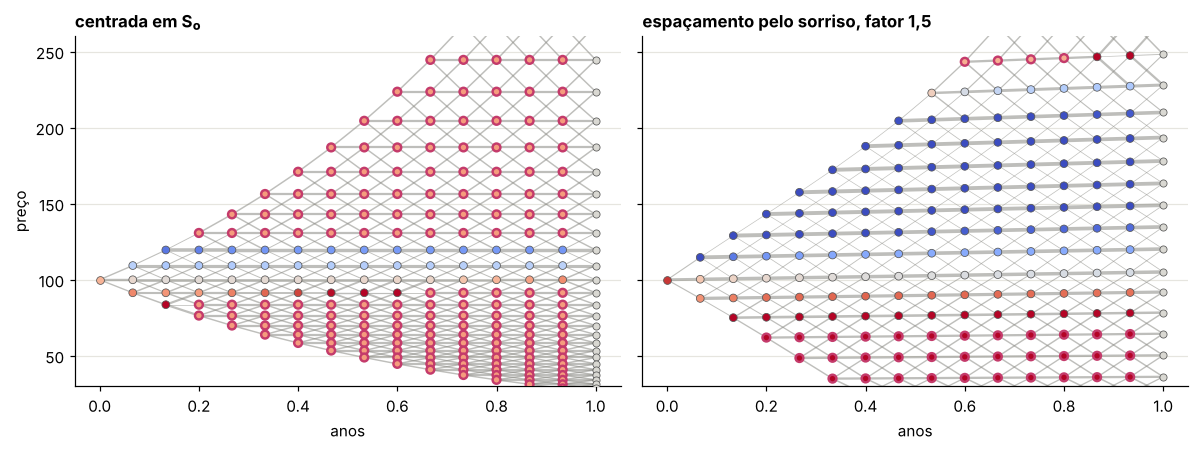

cor: vol local (azul abaixo, vermelho acima de 20%); borda magenta = override


In [9]:
FORTE = fazer_sorriso(S0, R, 0.20, -0.25, 0.20)
t15 = grade(1.0, 15)
linhas = []
for modo, fator in [("spot", 1.0), ("forward", 1.0), ("forward", 1.5), ("smile", 1.0), ("smile", 1.5)]:
    a_ = arvore_implicita(S0, R, t15, FORTE, espaco_estados(S0, R, t15, modo, FORTE, fator))
    e = [abs(vol_impl(preco_arvore(a_, lambda x: np.maximum(x - k, 0)), S0, k, 1.0, R) - FORTE(k, 1.0)) for k in (85, 90, 95)]
    linhas.append({"espaço": modo, "fator": fator, "nós com override": int(sum(o.sum() for o in a_["ovr"])),
                   "massa máx. em override (%)": 100 * massa_override(a_), "erro de vol K≤95 (p.p.)": 100 * max(e)})
comp = pd.DataFrame(linhas)
tabela(comp)
ok(comp["massa máx. em override (%)"].iloc[-1] < comp["massa máx. em override (%)"].iloc[0] / 4,
   "espaço pelo sorriso com fator 1,5 reduz a massa em override a menos de 1/4 da grade centrada em S₀")
ok(comp["erro de vol K≤95 (p.p.)"].iloc[-1] < comp["erro de vol K≤95 (p.p.)"].iloc[0] / 3,
   "e corta o erro nos strikes baixos a menos de 1/3")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, (modo, fator, tit) in zip(axs, [("spot", 1.0, "centrada em S₀"), ("smile", 1.5, "espaçamento pelo sorriso, fator 1,5")]):
    a_ = arvore_implicita(S0, R, t15, FORTE, espaco_estados(S0, R, t15, modo, FORTE, fator))
    desenhar_arvore(ax, t15, a_["S"], a_, s_ref=0.20)
    ax.set(title=tit, xlabel="anos", ylim=(30, 260))
    ax.set_xticks(t15[::3])
axs[0].set_ylabel("preço")
plt.tight_layout()
plt.show()
print("cor: vol local (azul abaixo, vermelho acima de 20%); borda magenta = override")

À esquerda, a grade horizontal acumula overrides (bordas magenta) logo acima e logo abaixo do miolo, onde ainda há probabilidade relevante. À direita, os nós se abrem para baixo, onde a vol implícita é maior, e os overrides recuam para regiões de pouca probabilidade (a tabela mostra a massa máxima caindo de 42% para menos de 8%). Essa é a recomendação prática de DKC: escolher o espaço de estados de modo que a variância pedida pelo sorriso caiba entre os sucessores.

## 6. Lendo a volatilidade local

Uma regra prática, devida a Derman, Kani e Zou, diz que a vol implícita de um strike $K$ é aproximadamente a **média** da vol local no caminho entre $S_0$ e $K$:

$$\sigma_{imp}(K) \approx \frac{1}{\ln K - \ln S_0}\int_{\ln S_0}^{\ln K}\sigma_{loc}(x)\,dx.$$

Se a vol local é linear em $x = \ln S$, com inclinação $\beta$, a média até $K$ cresce com inclinação $\beta/2$. Logo a vol local é inclinada **duas vezes** mais que a vol implícita. A regra vale perto do dinheiro e para prazos curtos.

,prazo T,data do nível,inclinação vol local,"razão sobre −0,15"
0,"0,250","0,062","-0,294","1,957"
1,"1,000","0,250","-0,285","1,897"


OK — vol local cerca de duas vezes mais inclinada que a implícita (razão entre 1,6 e 2,2)


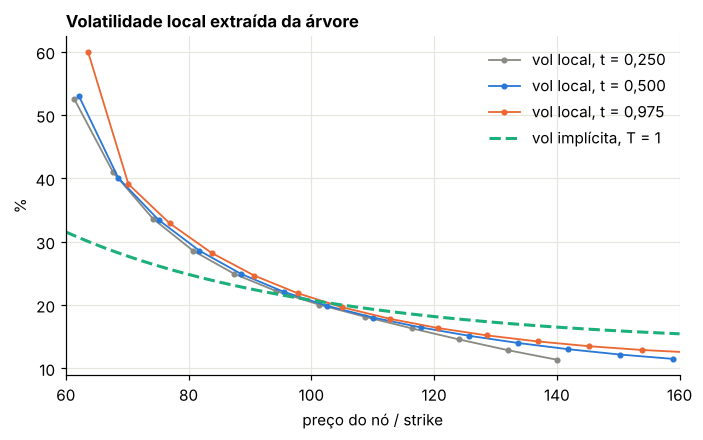

In [10]:
LINEAR = fazer_sorriso(S0, R, 0.20, -0.15, 0.0)
linhas = []
for Tq, Nq in [(0.25, 80), (1.0, 80)]:
    tq = grade(Tq, Nq)
    a_ = arvore_implicita(S0, R, tq, LINEAR, espaco_estados(S0, R, tq, "forward", LINEAR, 1.3))
    n = Nq // 4
    x = np.log(a_["S"][n] / (S0 * np.exp(R * tq[n])))
    sel = (np.abs(x) < 0.1) & ~a_["ovr"][n]
    beta = np.polyfit(x[sel], a_["vl"][n][sel], 1)[0]
    linhas.append({"prazo T": Tq, "data do nível": tq[n], "inclinação vol local": beta, "razão sobre −0,15": beta / -0.15})
regra = pd.DataFrame(linhas)
tabela(regra)
ok(regra["razão sobre −0,15"].between(1.6, 2.2).all(), "vol local cerca de duas vezes mais inclinada que a implícita (razão entre 1,6 e 2,2)")

fig, ax = plt.subplots()
for n, cor in [(10, CINZA), (20, AZUL), (39, LARANJA)]:
    sel = (arv["lam"][n] > 1e-4 * arv["lam"][n].max()) & ~arv["ovr"][n]
    ax.plot(arv["S"][n][sel], 100 * arv["vl"][n][sel], "o-", ms=3, lw=1.2, color=cor, label=f"vol local, t = {f3(t40[n])}")
KK = np.linspace(60, 160, 101)
ax.plot(KK, 100 * SORRISO(KK, 1.0), color=VERDE, ls="--", label="vol implícita, T = 1")
ax.set(title="Volatilidade local extraída da árvore", xlabel="preço do nó / strike", ylabel="%", xlim=(60, 160))
ax.legend()
plt.show()

A vol local é mais inclinada e, nas pontas, bem mais alta que a implícita. É por isso que as pontas da árvore são o lugar natural dos overrides: a variância pedida cresce mais depressa que o espaçamento.

## 7. Precificar na árvore implícita

A árvore calibrada serve para o que Black-Scholes com uma vol só não consegue: precificar, de forma consistente com todo o sorriso, contratos cujo valor depende da trajetória ou do exercício antecipado. Comparamos com uma árvore trinomial de vol constante igual à vol ATM. As duas concordam na call ATM e discordam no resto.

In [11]:
plano_atm = fazer_sorriso(S0, R, float(SORRISO(S0 * np.exp(R), 1.0)))
arv_c = arvore_implicita(S0, R, t40, plano_atm, espaco_estados(S0, R, t40, "smile", SORRISO, FATOR))

contratos = {
    "put europeia K = 90": dict(payoff=lambda x: np.maximum(90 - x, 0)),
    "put americana K = 90": dict(payoff=lambda x: np.maximum(90 - x, 0), americana=True),
    "put americana K = 100": dict(payoff=lambda x: np.maximum(100 - x, 0), americana=True),
    "call europeia K = 100": dict(payoff=lambda x: np.maximum(x - 100, 0)),
    "call down-and-out K = 100, B = 85": dict(payoff=lambda x: np.maximum(x - 100, 0), barreira=85.0),
    "call europeia K = 110": dict(payoff=lambda x: np.maximum(x - 110, 0)),
}
linhas = []
for nome, kw in contratos.items():
    linhas.append({"contrato": nome, "vol constante (ATM)": preco_arvore(arv_c, **kw), "árvore implícita": preco_arvore(arv, **kw)})
prec = pd.DataFrame(linhas)
prec["diferença"] = prec["árvore implícita"] - prec["vol constante (ATM)"]
tabela(prec)

pe = prec.set_index("contrato")["árvore implícita"]
ok(pe["put americana K = 90"] >= pe["put europeia K = 90"], "americana ≥ europeia na árvore implícita")
ok(prec.loc[0, "diferença"] > 0 and prec.loc[5, "diferença"] < 0,
   "com inclinação negativa, a put fora do dinheiro fica mais cara e a call fora do dinheiro mais barata")
ok(abs(pe["put europeia K = 90"] - bs(S0, 90, 1.0, R, SORRISO(90, 1.0), "put")) < 0.05,
   "a put europeia de K = 90 sai da árvore implícita a menos de 5 centavos do preço de mercado")

,contrato,vol constante (ATM),árvore implícita,diferença
0,put europeia K = 90,"2,350","3,062","0,713"
1,put americana K = 90,"2,512","3,176","0,664"
2,put americana K = 100,"6,181","6,337","0,156"
3,call europeia K = 100,"10,551","10,837","0,286"
4,"call down-and-out K = 100, B = 85","10,370","10,416","0,046"
5,call europeia K = 110,"6,157","5,911","-0,246"


OK — americana ≥ europeia na árvore implícita
OK — com inclinação negativa, a put fora do dinheiro fica mais cara e a call fora do dinheiro mais barata
OK — a put europeia de K = 90 sai da árvore implícita a menos de 5 centavos do preço de mercado


A call com barreira baixa pede uma leitura cuidadosa. Em valor absoluto ela quase não muda, mas isso esconde dois efeitos opostos: a call europeia de strike 100 já é mais cara na árvore implícita (a vol de mercado em $K = 100$ é maior que a ATM-forward), e a barreira tira dela uma fatia maior. A medida limpa é a fração do valor da call que a barreira destrói.

In [12]:
fracao = 1 - prec.set_index("contrato").loc["call down-and-out K = 100, B = 85"] / prec.set_index("contrato").loc["call europeia K = 100"]
print("fração do valor da call europeia perdida com a barreira:")
print("  vol constante:", f3(100 * fracao["vol constante (ATM)"]), "%   árvore implícita:", f3(100 * fracao["árvore implícita"]), "%")
ok(fracao["árvore implícita"] > fracao["vol constante (ATM)"], "a barreira destrói uma fração maior do valor na árvore implícita")

fração do valor da call europeia perdida com a barreira:
  vol constante: 1,714 %   árvore implícita: 3,884 %
OK — a barreira destrói uma fração maior do valor na árvore implícita


A vol local alta perto de 85 torna mais provável tocar a barreira do que numa árvore de vol constante. Duas árvores que concordam na call ATM dão preços diferentes para o contrato com barreira: é **risco de modelo**, e só a árvore implícita é consistente com as puts de strike baixo que o mercado está cotando.

## 8. Widget interativo: construa e desenhe a sua árvore

O widget abaixo usa **o mesmo algoritmo** das Seções 2 a 5, reescrito em JavaScript para rodar direto no navegador: funciona na página do livro, sem kernel, e também no Jupyter e no Colab. Mexa nos controles e a árvore é reconstruída na hora.

- **Botões de cenário.** "Figura (a)" monta a árvore de passos 0, 1, 3 e 6 meses com rótulos de preço; "Figura (b)" monta a árvore de 10 passos que curva com o forward; "Sorriso forte" mostra os overrides de uma grade mal escolhida, e "espaço ajustado" mostra a correção.
- **Passe o mouse num nó** para ver o preço, o preço de Arrow-Debreu, o forward, as três probabilidades e a vol local.
- A espessura das arestas é proporcional à probabilidade; a cor do nó pode mostrar a vol local ou o preço de Arrow-Debreu; bordas magenta marcam overrides.
- Abaixo da árvore: as conferências da Seção 3 ($\Sigma\lambda$ e martingal), a tabela de reprecificação nos nós e o gráfico do sorriso contra a vol local.

Experimentos sugeridos: (1) com "Volatilidade constante", aumente a inclinação e veja a vol local se abrir com o dobro da inclinação; (2) em "Sorriso forte", troque o espaço de estados e o fator até os overrides sumirem do miolo; (3) mude a grade para "crescente" e veja os degraus crescerem com o passo.

In [13]:
# Widget interativo: o algoritmo das Seções 2 a 5 em JavaScript, para rodar no navegador sem kernel.
import uuid
from IPython.display import HTML

_WIDGET = r'''<div id="dkc-__ID__" class="dkc-widget">
<style>
#dkc-__ID__{--azul:#2a78d6;--laranja:#eb6834;--verde:#1baf7a;--cinza:#8a8a84;--mag:#c43b6b;font-family:inherit;font-size:13px;line-height:1.35;max-width:860px;color:inherit}
#dkc-__ID__ .ctl{display:grid;grid-template-columns:repeat(auto-fill,minmax(200px,1fr));gap:6px 18px;margin:6px 0 10px}
#dkc-__ID__ .ctl label{display:flex;flex-direction:column;gap:2px}
#dkc-__ID__ .ctl .lin{display:flex;justify-content:space-between}
#dkc-__ID__ .ctl output{font-variant-numeric:tabular-nums;font-weight:600}
#dkc-__ID__ input[type=range]{width:100%;accent-color:var(--azul)}
#dkc-__ID__ select{font:inherit;padding:2px 4px;border-radius:4px;border:1px solid #bbb;background:transparent;color:inherit}
#dkc-__ID__ select option{color:#222}
#dkc-__ID__ .pre{display:flex;flex-wrap:wrap;gap:6px;margin:4px 0}
#dkc-__ID__ .pre button{font:inherit;padding:4px 10px;border-radius:14px;border:1px solid var(--azul);background:transparent;color:var(--azul);cursor:pointer}
#dkc-__ID__ .pre button:hover{background:var(--azul);color:#fff}
#dkc-__ID__ svg{display:block;width:100%;height:auto;overflow:visible}
#dkc-__ID__ svg text{fill:currentColor;font-family:inherit}
#dkc-__ID__ .tip{position:absolute;pointer-events:none;background:rgba(30,30,30,.92);color:#fff;padding:6px 8px;border-radius:6px;font-size:12px;white-space:nowrap;display:none;z-index:5}
#dkc-__ID__ .stats{display:flex;flex-wrap:wrap;gap:4px 18px;margin:6px 0;font-variant-numeric:tabular-nums}
#dkc-__ID__ .stats b{font-weight:600}
#dkc-__ID__ .baixo{display:grid;grid-template-columns:minmax(260px,1fr) minmax(260px,1fr);gap:14px;align-items:start}
#dkc-__ID__ table{border-collapse:collapse;font-variant-numeric:tabular-nums;width:100%}
#dkc-__ID__ td,#dkc-__ID__ th{padding:2px 8px;text-align:right;border-bottom:1px solid rgba(128,128,128,.25)}
#dkc-__ID__ .leg{display:flex;gap:14px;flex-wrap:wrap;font-size:12px;opacity:.85}
#dkc-__ID__ .sw{display:inline-block;width:10px;height:10px;border-radius:50%;margin-right:4px;vertical-align:-1px}
@media (max-width:640px){#dkc-__ID__ .baixo{grid-template-columns:1fr}}
</style>
<div class="pre">
 <button data-p="a">Figura (a): passos 0–1–3–6</button>
 <button data-p="b">Figura (b): árvore que curva</button>
 <button data-p="c">Sorriso forte (overrides)</button>
 <button data-p="e">Sorriso forte, espaço ajustado</button>
 <button data-p="d">Volatilidade constante</button>
</div>
<div class="ctl">
 <label><span class="lin">Preço inicial S₀ <output data-o="S0"></output></span><input type="range" data-k="S0" min="50" max="200" step="1"></label>
 <label><span class="lin">Juros r (% a.a.) <output data-o="r"></output></span><input type="range" data-k="r" min="0" max="15" step="0.25"></label>
 <label><span class="lin">Prazo T (anos) <output data-o="T"></output></span><input type="range" data-k="T" min="0.25" max="10" step="0.25"></label>
 <label><span class="lin">Passos N <output data-o="N"></output></span><input type="range" data-k="N" min="2" max="40" step="1"></label>
 <label><span class="lin">Vol ATM (%) <output data-o="sa"></output></span><input type="range" data-k="sa" min="5" max="60" step="0.5"></label>
 <label><span class="lin">Inclinação do sorriso <output data-o="inc"></output></span><input type="range" data-k="inc" min="-0.6" max="0.6" step="0.01"></label>
 <label><span class="lin">Convexidade do sorriso <output data-o="cv"></output></span><input type="range" data-k="cv" min="0" max="1" step="0.05"></label>
 <label><span class="lin">Fator de espaçamento <output data-o="f"></output></span><input type="range" data-k="f" min="0.6" max="2.5" step="0.05"></label>
 <label>Grade de tempo<select data-k="grade"><option value="uniforme">uniforme</option><option value="crescente">crescente (0, 1, 3, 6, 10…)</option></select></label>
 <label>Espaço de estados<select data-k="modo"><option value="spot">centrado em S₀</option><option value="forward">centrado no forward (curva)</option><option value="smile">espaçamento pelo sorriso</option></select></label>
 <label>Eixo vertical<select data-k="esc"><option value="preco">preço</option><option value="log">log-preço</option></select></label>
 <label>Cor dos nós<select data-k="cor"><option value="vl">volatilidade local</option><option value="ad">preço de Arrow-Debreu</option><option value="nada">nenhuma</option></select></label>
 <label><span class="lin">Rótulos com o preço (até 8 passos) <input type="checkbox" data-k="rot"></span></label>
</div>
<div style="position:relative"><svg class="arv" viewBox="0 0 820 440"></svg><div class="tip"></div></div>
<div class="leg"></div>
<div class="stats"></div>
<div class="baixo">
 <div><svg class="smile" viewBox="0 0 400 210"></svg></div>
 <div class="rep"></div>
</div>
<script>
(function(){
/*NUCLEO-INICIO*/
function cnd(x){var a=Math.abs(x),c;if(a>37){c=0}else{var e=Math.exp(-a*a/2),b;
 if(a<7.07106781186547){b=3.52624965998911e-2*a+0.700383064443688;b=b*a+6.37396220353165;b=b*a+33.912866078383;b=b*a+112.079291497871;b=b*a+221.213596169931;b=b*a+220.206867912376;c=e*b;
 b=8.83883476483184e-2*a+1.75566716318264;b=b*a+16.064177579207;b=b*a+86.7807322029461;b=b*a+296.564248779674;b=b*a+637.333633378831;b=b*a+793.826512519948;b=b*a+440.413735824752;c=c/b;}
 else{b=a+0.65;b=a+4/b;b=a+3/b;b=a+2/b;b=a+1/b;c=e/b/2.506628274631;}}
 return x>0?1-c:c;}
function bs(S,K,T,r,s,call){var d1=(Math.log(S/K)+(r+0.5*s*s)*T)/(s*Math.sqrt(T)),d2=d1-s*Math.sqrt(T);
 return call?S*cnd(d1)-K*Math.exp(-r*T)*cnd(d2):K*Math.exp(-r*T)*cnd(-d2)-S*cnd(-d1);}
function fazerSmile(S0,r,sa,inc,cv){return function(K,t){var m=Math.log(K/(S0*Math.exp(r*t)));return Math.max(sa+inc*m+cv*m*m,0.01);};}
function grade(T,N,tipo){var t=[];for(var k=0;k<=N;k++)t.push(tipo==="crescente"?T*k*(k+1)/(N*(N+1)):T*k/N);return t;}
function espacoEstados(S0,r,t,f,modo,smile){var niv=[[S0]];
 for(var n=1;n<t.length;n++){var dt=t[n]-t[n-1],c=Math.log(S0)+((modo==="spot")?0:r*t[n]),x=new Array(2*n+1);
  if(modo!=="smile"){var h=f*smile(S0*Math.exp(r*t[n]),t[n])*Math.sqrt(3*dt);for(var k=0;k<2*n+1;k++)x[k]=c+(n-k)*h;}
  else{x[n]=c;var hm=4*smile(S0*Math.exp(r*t[n]),t[n])*Math.sqrt(3*dt);
   for(var k=n-1;k>=0;k--)x[k]=x[k+1]+Math.min(f*smile(Math.exp(x[k+1]),t[n])*Math.sqrt(3*dt),hm);
   for(var k=n+1;k<2*n+1;k++)x[k]=x[k-1]-Math.min(f*smile(Math.exp(x[k-1]),t[n])*Math.sqrt(3*dt),hm);}
  niv.push(x.map(Math.exp));}
 return niv;}
function override(F,a,b,c){if(F>=a)return[1,0];if(F<=c)return[0,1];
 if(F>b)return[0.5*((F-b)/(a-b)+(F-c)/(a-c)),0.5*(a-F)/(a-c)];
 return[0.5*(F-c)/(a-c),0.5*((b-F)/(b-c)+(a-F)/(a-c))];}
function arvoreImplicita(S0,r,t,smile,niv){var N=t.length-1,lam=[[1]],P=[],Q=[],VL=[],OV=[];
 for(var n=0;n<N;n++){var S=niv[n],S1=niv[n+1],L=lam[n],dt=t[n+1]-t[n],t1=t[n+1],cr=Math.exp(r*dt),m=S.length,F=S.map(function(s){return s*cr;});
  var p=new Array(m),q=new Array(m),o=new Array(m),ac=0,i,j,K;
  for(i=0;i<=(m-1)/2;i++){K=S1[i+1];var C=bs(S0,K,t1,r,smile(K,t1),true);
   p[i]=(cr*C-ac)/(L[i]*(S1[i]-K));q[i]=(F[i]-p[i]*(S1[i]-K)-K)/(S1[i+2]-K);
   ac=0;for(j=0;j<=i;j++)ac+=L[j]*(F[j]-S1[i+2]);}
  ac=0;for(i=m-1;i>(m-1)/2;i--){K=S1[i+1];var Pp=bs(S0,K,t1,r,smile(K,t1),false);
   q[i]=(cr*Pp-ac)/(L[i]*(K-S1[i+2]));p[i]=(F[i]+q[i]*(K-S1[i+2])-K)/(S1[i]-K);
   ac=0;for(j=i;j<m;j++)ac+=L[j]*(S1[i]-F[j]);}
  var vl=new Array(m),L1=new Array(m+2).fill(0);
  for(i=0;i<m;i++){o[i]=false;if(!(isFinite(p[i])&&isFinite(q[i]))||p[i]<0||q[i]<0||p[i]+q[i]>1){var pq=override(F[i],S1[i],S1[i+1],S1[i+2]);p[i]=pq[0];q[i]=pq[1];o[i]=true;}
   var pm=1-p[i]-q[i];vl[i]=Math.sqrt((p[i]*Math.pow(S1[i]-F[i],2)+pm*Math.pow(S1[i+1]-F[i],2)+q[i]*Math.pow(S1[i+2]-F[i],2))/(F[i]*F[i]*dt));
   L1[i]+=L[i]*p[i]/cr;L1[i+1]+=L[i]*pm/cr;L1[i+2]+=L[i]*q[i]/cr;}
  lam.push(L1);P.push(p);Q.push(q);VL.push(vl);OV.push(o);}
 return{S:niv,lam:lam,p:P,q:Q,vl:VL,ovr:OV,t:t,r:r};}
function precoArvore(a,payoff,amer){var N=a.t.length-1,V=a.S[N].map(payoff);
 for(var n=N-1;n>=0;n--){var d=Math.exp(-a.r*(a.t[n+1]-a.t[n])),W=new Array(a.S[n].length);
  for(var i=0;i<W.length;i++){W[i]=d*(a.p[n][i]*V[i]+(1-a.p[n][i]-a.q[n][i])*V[i+1]+a.q[n][i]*V[i+2]);if(amer)W[i]=Math.max(W[i],payoff(a.S[n][i]));}V=W;}
 return V[0];}
/*NUCLEO-FIM*/
var raiz=document.getElementById("dkc-__ID__");
var estado={S0:100,r:5,T:1,N:8,sa:20,inc:-0.15,cv:0.1,f:1.3,grade:"uniforme",modo:"smile",esc:"preco",cor:"vl",rot:false};
var PRE={a:{S0:100,r:3,T:0.5,N:3,sa:10,inc:-0.05,cv:0,f:1,grade:"crescente",modo:"spot",esc:"preco",cor:"vl",rot:true},
 b:{S0:100,r:6,T:10,N:10,sa:12,inc:0,cv:0,f:1,grade:"uniforme",modo:"forward",esc:"preco",cor:"ad",rot:false},
 c:{S0:100,r:5,T:1,N:15,sa:20,inc:-0.25,cv:0.2,f:1,grade:"uniforme",modo:"spot",esc:"preco",cor:"vl",rot:false},
 e:{S0:100,r:5,T:1,N:15,sa:20,inc:-0.25,cv:0.2,f:1.5,grade:"uniforme",modo:"smile",esc:"preco",cor:"vl",rot:false},
 d:{S0:100,r:5,T:1,N:6,sa:20,inc:0,cv:0,f:1,grade:"uniforme",modo:"spot",esc:"preco",cor:"vl",rot:true}};
function br(x,d){if(!isFinite(x))return"n/d";if(Math.abs(x)<0.5*Math.pow(10,-d))x=0;return x.toFixed(d).replace("-","−").replace(".",",");}
function fmtO(k,v){if(k==="r"||k==="sa")return br(+v,2)+"%";if(k==="N")return String(v);if(k==="S0")return br(+v,0);return br(+v,2);}
function sync(){raiz.querySelectorAll("[data-k]").forEach(function(el){var k=el.dataset.k;if(el.type==="checkbox")el.checked=!!estado[k];else el.value=estado[k];});
 raiz.querySelectorAll("output").forEach(function(o){o.textContent=fmtO(o.dataset.o,estado[o.dataset.o]);});}
function NS(tag,at){var e=document.createElementNS("http://www.w3.org/2000/svg",tag);for(var k in at)e.setAttribute(k,at[k]);return e;}
function mix(c1,c2,u){var a=[1,3,5].map(function(i){return parseInt(c1.substr(i,2),16)}),b=[1,3,5].map(function(i){return parseInt(c2.substr(i,2),16)});
 return"rgb("+a.map(function(x,i){return Math.round(x+(b[i]-x)*u)}).join(",")+")";}
function corVL(v,ref){var u=Math.max(-1,Math.min(1,(v-ref)/(0.5*ref)));return u<0?mix("#d9d8d2","#2a78d6",-u):mix("#d9d8d2","#eb6834",u);}
function ivol(preco,S,K,T,r){var lo=1e-4,hi=3;if(preco<=Math.max(S-K*Math.exp(-r*T),0)+1e-12)return NaN;for(var it=0;it<80;it++){var m=(lo+hi)/2;if(bs(S,K,T,r,m,true)>preco)hi=m;else lo=m;}return(lo+hi)/2;}
function desenhar(){
 var e=estado,r=e.r/100,sm=fazerSmile(e.S0,r,e.sa/100,e.inc,e.cv),t=grade(e.T,e.N,e.grade),niv=espacoEstados(e.S0,r,t,e.f,e.modo,sm),a=arvoreImplicita(e.S0,r,t,sm,niv),N=e.N;
 var svg=raiz.querySelector("svg.arv");while(svg.firstChild)svg.removeChild(svg.firstChild);
 var W=820,H=440,ml=58,mr=20,mt=16,mb=44,lg=e.esc==="log";
 var ys=[];niv.forEach(function(l){l.forEach(function(s){ys.push(lg?Math.log(s):s)})});
 var y0=Math.min.apply(null,ys),y1=Math.max.apply(null,ys),pad=(y1-y0)*0.04||1;y0-=pad;y1+=pad;if(!lg)y0=Math.max(y0,0);
 var X=function(tt){return ml+(W-ml-mr)*tt/e.T},Y=function(s){var v=lg?Math.log(s):s;return mt+(H-mt-mb)*(1-(v-y0)/(y1-y0))};
 // eixos
 var ax=NS("g",{});svg.appendChild(ax);
 ax.appendChild(NS("line",{x1:ml,x2:W-mr,y1:H-mb+8,y2:H-mb+8,stroke:"currentColor","stroke-opacity":.5}));
 var meses=e.T<=2,passo=Math.ceil((N+1)/14);
 t.forEach(function(tt,k){if(k%passo&&k!==N)return;var x=X(tt);ax.appendChild(NS("line",{x1:x,x2:x,y1:H-mb+4,y2:H-mb+12,stroke:"currentColor","stroke-opacity":.5}));
  var tx=NS("text",{x:x,y:H-mb+26,"text-anchor":"middle","font-size":11});var v=meses?tt*12:tt;tx.textContent=(Math.abs(v-Math.round(v))<1e-9?String(Math.round(v)):br(v,2));ax.appendChild(tx);});
 var lx=NS("text",{x:(ml+W-mr)/2,y:H-4,"text-anchor":"middle","font-size":11,"fill-opacity":.7});lx.textContent=meses?"tempo (meses)":"tempo (anos)";ax.appendChild(lx);
 for(var g=0;g<=4;g++){var v=y0+(y1-y0)*g/4,yy=mt+(H-mt-mb)*(1-g/4),sv=lg?Math.exp(v):v;
  ax.appendChild(NS("line",{x1:ml,x2:W-mr,y1:yy,y2:yy,stroke:"currentColor","stroke-opacity":.08}));
  var ty=NS("text",{x:ml-6,y:yy+4,"text-anchor":"end","font-size":11});ty.textContent=br(sv,sv<10?2:0);ax.appendChild(ty);}
 // arestas
 var ga=NS("g",{});svg.appendChild(ga);
 for(var n=0;n<N;n++)for(var i=0;i<niv[n].length;i++){var pr=[a.p[n][i],1-a.p[n][i]-a.q[n][i],a.q[n][i]];
  for(var k=0;k<3;k++){if(pr[k]<1e-12)continue;ga.appendChild(NS("line",{x1:X(t[n]),y1:Y(niv[n][i]),x2:X(t[n+1]),y2:Y(niv[n+1][i+k]),stroke:"currentColor","stroke-opacity":0.18+0.5*Math.min(pr[k],1),"stroke-width":0.5+2.2*pr[k]}));}}
 // nós
 var gn=NS("g",{});svg.appendChild(gn);var tip=raiz.querySelector(".tip");
 var rad=N<=10?4.5:(N<=20?3.4:2.6),lmax=0;a.lam.forEach(function(l){l.forEach(function(v){lmax=Math.max(lmax,v)})});
 var vlN=a.vl.slice();
 for(var n=0;n<=N;n++)for(var i=0;i<niv[n].length;i++){(function(n,i){
  var s=niv[n][i],lam=a.lam[n][i],ov=n<N&&a.ovr[n][i],vl=n<N?a.vl[n][i]:NaN,fill;
  if(e.cor==="vl")fill=n<N?corVL(vl,e.sa/100):"#d9d8d2";else if(e.cor==="ad")fill=mix("#e8eef7","#2a78d6",Math.pow(lam/lmax,0.35));else fill="#2a78d6";
  var c=NS("circle",{cx:X(t[n]),cy:Y(s),r:rad,fill:fill,stroke:ov?"#c43b6b":"rgba(0,0,0,.35)","stroke-width":ov?2:0.6});
  c.style.cursor="pointer";
  c.addEventListener("mouseenter",function(ev){var h="<b>nó ("+n+", "+i+")</b> · t = "+br(t[n],3)+"<br>S = "+br(s,3)+"<br>Arrow-Debreu λ = "+br(lam,5);
   if(n<N){var p=a.p[n][i],q=a.q[n][i];h+="<br>forward = "+br(s*Math.exp(r*(t[n+1]-t[n])),3)+"<br>p<sub>sobe</sub> = "+br(p,3)+" · p<sub>meio</sub> = "+br(1-p-q,3)+" · p<sub>desce</sub> = "+br(q,3)+"<br>vol local = "+br(100*vl,2)+"%"+(ov?"<br><span style='color:#ff9ab8'>override (probabilidade negativa corrigida)</span>":"");}
   tip.innerHTML=h;tip.style.display="block";});
  c.addEventListener("mousemove",function(ev){var b=raiz.querySelector("svg.arv").parentNode.getBoundingClientRect();var x=ev.clientX-b.left+12,y=ev.clientY-b.top+12;if(x>b.width-230)x-=250;tip.style.left=x+"px";tip.style.top=y+"px";});
  c.addEventListener("mouseleave",function(){tip.style.display="none";});
  gn.appendChild(c);
  if(e.rot&&N<=8){var tx=NS("text",{x:X(t[n]),y:Y(s)-rad-3,"text-anchor":"middle","font-size":11});tx.textContent=br(s,2);gn.appendChild(tx);}
 })(n,i);}
 // legenda
 var leg=raiz.querySelector(".leg");
 leg.innerHTML=(e.cor==="vl"?"<span><span class='sw' style='background:#2a78d6'></span>vol local abaixo da ATM</span><span><span class='sw' style='background:#d9d8d2'></span>≈ ATM</span><span><span class='sw' style='background:#eb6834'></span>acima da ATM</span>":
  e.cor==="ad"?"<span><span class='sw' style='background:#2a78d6'></span>cor mais forte = preço de Arrow-Debreu maior</span>":"")+
  "<span><span class='sw' style='background:transparent;border:2px solid #c43b6b'></span>override</span><span>espessura da aresta ∝ probabilidade</span>";
 // estatísticas
 var nov=0,tot=0,mov=0;for(var n=0;n<N;n++){var m=0;for(var i=0;i<a.ovr[n].length;i++){tot++;if(a.ovr[n][i]){nov++;m+=a.lam[n][i];}}mov=Math.max(mov,m/a.lam[n].reduce(function(x,y){return x+y},0));}
 var sl=a.lam[N].reduce(function(x,y){return x+y},0),fw=0;a.lam[N].forEach(function(l,i){fw+=l*niv[N][i]});
 var K0=e.S0,pa=precoArvore(a,function(s){return Math.max(K0-s,0)},true),pe=precoArvore(a,function(s){return Math.max(K0-s,0)},false);
 raiz.querySelector(".stats").innerHTML="<span>Σλ(T) = <b>"+br(sl,3)+"</b> · e<sup>−rT</sup> = <b>"+br(Math.exp(-r*e.T),3)+"</b></span><span>Σλ·S(T) = <b>"+br(fw,3)+"</b> (deve ser S₀)</span>"+
  "<span>overrides: <b>"+nov+"</b> de "+tot+" nós (massa máx. num passo: "+br(100*mov,2)+"%)</span><span>put ATM: europeia <b>"+br(pe,3)+"</b> · americana <b>"+br(pa,3)+"</b></span>";
 // reprecificação nos strikes dos nós do último nível
 var Fw=e.S0*Math.exp(r*e.T),rows="",ks=[];for(var k=Math.max(1,N-2);k<=Math.min(2*N-1,N+2);k++)ks.push(niv[N][k]);
 ks.forEach(function(K){var pc=precoArvore(a,function(s){return Math.max(s-K,0)},false),iv=ivol(pc,e.S0,K,e.T,r);
  rows+="<tr><td>"+br(K,2)+"</td><td>"+br(100*sm(K,e.T),2)+"%</td><td>"+br(100*iv,2)+"%</td><td>"+br(100*(iv-sm(K,e.T)),2)+"</td></tr>";});
 raiz.querySelector(".rep").innerHTML="<div style='font-weight:600;margin:2px 0 4px'>Calls com vencimento T e strikes nos nós: a árvore reprecifica o sorriso?</div><table><tr><th>strike (nó)</th><th>vol de mercado</th><th>vol da árvore</th><th>dif. (p.p.)</th></tr>"+rows+
  "</table><div style='font-size:12px;opacity:.75;margin-top:4px'>Nos nós o ajuste é exato, salvo override no último passo. Entre os nós, o preço da árvore interpola o payoff e aparece erro de discretização.</div>";
 // sorriso x vol local
 var s2=raiz.querySelector("svg.smile");while(s2.firstChild)s2.removeChild(s2.firstChild);
 var nm=Math.max(1,Math.floor(N/2)),tm=t[nm],pts=[];for(var i=0;i<niv[nm].length;i++){if(a.lam[nm][i]>1e-4*Math.max.apply(null,a.lam[nm]))pts.push([niv[nm][i],a.vl[nm][i],a.ovr[nm][i]]);}
 var kmin=Math.min.apply(null,pts.map(function(p){return p[0]}).concat([Fw*0.7])),kmax=Math.max.apply(null,pts.map(function(p){return p[0]}).concat([Fw*1.3]));
 var cur=[];for(var j=0;j<=60;j++){var K=kmin+(kmax-kmin)*j/60;cur.push([K,sm(K,e.T)]);}
 var vs=cur.map(function(c){return c[1]}).concat(pts.map(function(p){return p[1]})),v0=Math.min.apply(null,vs)*0.9,v1=Math.max.apply(null,vs)*1.05;
 var X2=function(k){return 46+(400-56)*(k-kmin)/(kmax-kmin)},Y2=function(v){return 14+(210-48)*(1-(v-v0)/(v1-v0))};
 for(var g=0;g<=3;g++){var v=v0+(v1-v0)*g/3,yy=Y2(v);s2.appendChild(NS("line",{x1:46,x2:390,y1:yy,y2:yy,stroke:"currentColor","stroke-opacity":.08}));var tx=NS("text",{x:42,y:yy+4,"text-anchor":"end","font-size":10});tx.textContent=br(100*v,0)+"%";s2.appendChild(tx);}
 [kmin,(kmin+kmax)/2,kmax].forEach(function(k){var tx=NS("text",{x:X2(k),y:200,"text-anchor":"middle","font-size":10});tx.textContent=br(k,0);s2.appendChild(tx);});
 s2.appendChild(NS("path",{d:"M"+cur.map(function(c){return X2(c[0])+","+Y2(c[1])}).join("L"),fill:"none",stroke:"#2a78d6","stroke-width":2}));
 pts.forEach(function(p){s2.appendChild(NS("circle",{cx:X2(p[0]),cy:Y2(p[1]),r:3,fill:"#eb6834",stroke:p[2]?"#c43b6b":"none","stroke-width":1.5}));});
 var tt=NS("text",{x:46,y:10,"font-size":11,"font-weight":600});tt.textContent="sorriso em T (linha) × vol local em t = "+br(tm,2)+" (pontos)";s2.appendChild(tt);
}
raiz.querySelectorAll("[data-k]").forEach(function(el){el.addEventListener("input",function(){var k=el.dataset.k;estado[k]=el.type==="checkbox"?el.checked:(el.tagName==="SELECT"?el.value:+el.value);sync();desenhar();});});
raiz.querySelectorAll(".pre button").forEach(function(b){b.addEventListener("click",function(){Object.assign(estado,PRE[b.dataset.p]);sync();desenhar();});});
sync();desenhar();
})();
</script>
</div>
'''


def widget_arvore():
    """Mostra o widget com um identificador único (pode ser chamado mais de uma vez)."""
    display(HTML(_WIDGET.replace("__ID__", uuid.uuid4().hex[:8])))


widget_arvore()

### Conferência: o JavaScript do widget contra o Python

Se o Node.js estiver instalado, a célula abaixo roda o núcleo numérico do widget e compara os preços de Arrow-Debreu e uma put americana com os desta página. Sem Node.js, ela só avisa e segue.

In [14]:
import json, shutil, subprocess

if shutil.which("node"):
    nucleo = _WIDGET.split("/*NUCLEO-INICIO*/")[1].split("/*NUCLEO-FIM*/")[0]
    js = nucleo + """
var sm=fazerSmile(100,0.05,0.2,-0.15,0.1),t=grade(1,40,"uniforme"),niv=espacoEstados(100,0.05,t,1.3,"smile",sm),a=arvoreImplicita(100,0.05,t,sm,niv);
console.log(JSON.stringify({lam:a.lam[40],put:precoArvore(a,function(s){return Math.max(90-s,0)},true)}));"""
    saida = json.loads(subprocess.run(["node", "-e", js], capture_output=True, text=True, check=True).stdout)
    dif_l = np.max(np.abs(np.array(saida["lam"]) - arv["lam"][-1]))
    dif_p = abs(saida["put"] - pe["put americana K = 90"])
    print(f"maior diferença em λ: {dif_l:.1e} · diferença na put americana: {dif_p:.1e}")
    print("JavaScript e Python coincidem." if max(dif_l, dif_p) < 1e-10 else "ATENÇÃO: JavaScript e Python divergem.")
else:
    print("Node.js não encontrado: conferência pulada (o widget continua funcionando no navegador).")

maior diferença em λ: 4.1e-15 · diferença na put americana: 2.2e-15
JavaScript e Python coincidem.


## 9. Cuidados de implementação

- **Ordem dos nós.** As fórmulas de DKC supõem os nós em ordem decrescente e o nó $i$ ligado a $i$, $i+1$, $i+2$. Inverter a ordem troca o papel de calls e puts e é fonte comum de erro.
- **A soma acumulada muda de strike.** Em $\sum_{j<i}\lambda_j(F_j - s_{i+1})$, o strike é o do nó atual; não dá para acumular a soma do passo anterior sem corrigir o strike.
- **Preços de opções consistentes.** Se o sorriso de entrada tiver arbitragem (borboleta ou calendário), a árvore acusa com probabilidades negativas em série. O override esconde o sintoma, mas não corrige a superfície.
- **Overrides não são de graça.** Cada override abandona uma opção de mercado. Reporte sempre a massa de Arrow-Debreu em override, como fizemos, e não só a contagem.
- **Passos desiguais.** A grade crescente economiza nós em prazos longos, mas degraus que crescem muito de um nível para o outro afastam o nó do seu sucessor do meio e geram overrides.

## 10. Síntese

| etapa | o que se escolhe | o que se impõe |
|---|---|---|
| espaço de estados | datas, centro e espaçamento | 2n + 1 nós por nível, recombinação |
| probabilidades | — | forward e calls (em cima) ou puts (embaixo) com strike nos nós |
| Arrow-Debreu | — | indução para a frente, como no Módulo 18 |
| override | regra de DKC | só o forward, quando a opção não cabe |
| saída | — | vol local em cada nó, preços consistentes com o sorriso |

A árvore implícita é o modelo de volatilidade local em forma discreta. Ela reproduz por construção os preços de hoje, mas descreve mal a **dinâmica** do sorriso: quando o preço cai, a vol local prevê que o sorriso se desloque de um jeito que o mercado em geral não confirma. Por isso, para produtos sensíveis a vol futura (cliquets, opções sobre variância), entram os modelos de volatilidade estocástica dos Módulos 11 a 16.

## 11. Exercícios

**Exercício 1.** Mostre que, se em todos os nós vale a condição do forward, então $\sum_k \Lambda_k^{(n)} S_k^{(n)} = S_0$ em qualquer nível, com ou sem overrides.

<details><summary>Solução</summary>

Por indução. $\sum_k\Lambda_k s_k = e^{-r\Delta t}\sum_k\sum_i\lambda_i\pi_{i\to k}s_k = e^{-r\Delta t}\sum_i\lambda_iF_i = \sum_i\lambda_iS_i$. Na raiz, $\lambda = 1$ e $S = S_0$. O override também satisfaz o forward, por isso a identidade não depende dele.
</details>

**Exercício 2.** Troque, no código, as puts da metade de baixo por calls (use calls em todos os nós). Com o sorriso da Seção 4 e $N = 40$, o que acontece com o número de overrides? Por quê?

<details><summary>Solução</summary>

Os overrides aumentam na parte de baixo. Para strikes baixos, a call está muito dentro do dinheiro e $e^{r\Delta t}C - \sum_{j<i}\lambda_j(F_j - K)$ é a diferença de dois números grandes e quase iguais. O pequeno resto, dividido por $\lambda_i$ (também pequeno nas pontas), amplifica o erro numérico e o erro de discretização acumulado, e as probabilidades saem fora de $[0, 1]$.
</details>

**Exercício 3.** No widget, escolha "Figura (a)" e aumente a inclinação para $-0{,}5$. Em que nós surgem os overrides e por quê?

<details><summary>Solução</summary>

Com inclinação forte e só 3 passos, a variância pedida nos nós de baixo supera a que três sucessores tão próximos conseguem dar. No topo, a vol local cai muito e a deriva de juros, que a grade centrada em $S_0$ não absorve, impõe uma variância mínima. Trocar o espaço de estados para "centrado no forward" ou "pelo sorriso" alivia os dois lados.
</details>

**Exercício 4.** Precifique a call down-and-out da Seção 7 com $N = 20, 40, 80$. O preço converge de forma suave? Como melhorar?

<details><summary>Solução</summary>

Não: o preço oscila porque a barreira efetiva é o primeiro nível de nós abaixo de 85, que muda com $N$. A correção clássica é posicionar um nível de nós exatamente na barreira (o espaço de estados é livre em DKC, então basta ajustar o centro ou o espaçamento) ou interpolar entre duas árvores com barreiras efetivas acima e abaixo de $B$.
</details>

In [15]:
print(f"Módulo 20 concluído: {_checks['n']} verificações aprovadas.")

Módulo 20 concluído: 22 verificações aprovadas.
